In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)
pd.options.display.float_format = "{:,.2f}".format

df = pd.read_csv("../data/processed/rumah_clean.csv")

TARGET   = "price_in_rp"
NUMERIK  = ["land_size_m2", "building_size_m2", "bedrooms", "bathrooms", "carports", "garages"]
LOKASI   = "city"
KATEGORI = ["certificate", "property_condition", "furnishing"]
df.shape

(3172, 24)

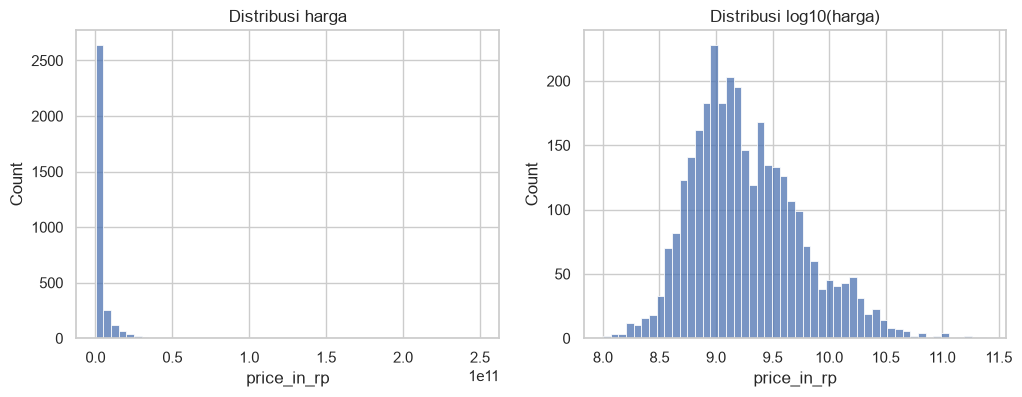

Median: 1555000000.0
Rata-rata: 4076831967.2131147
Skewness: 11.552727868035477 | setelah log: 0.6491504203706978


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=50, ax=ax[0]);           ax[0].set_title("Distribusi harga")
sns.histplot(np.log10(df[TARGET]), bins=50, ax=ax[1]); ax[1].set_title("Distribusi log10(harga)")
plt.show()

print("Median:", df[TARGET].median())
print("Rata-rata:", df[TARGET].mean())
print("Skewness:", df[TARGET].skew(), "| setelah log:", np.log(df[TARGET]).skew())

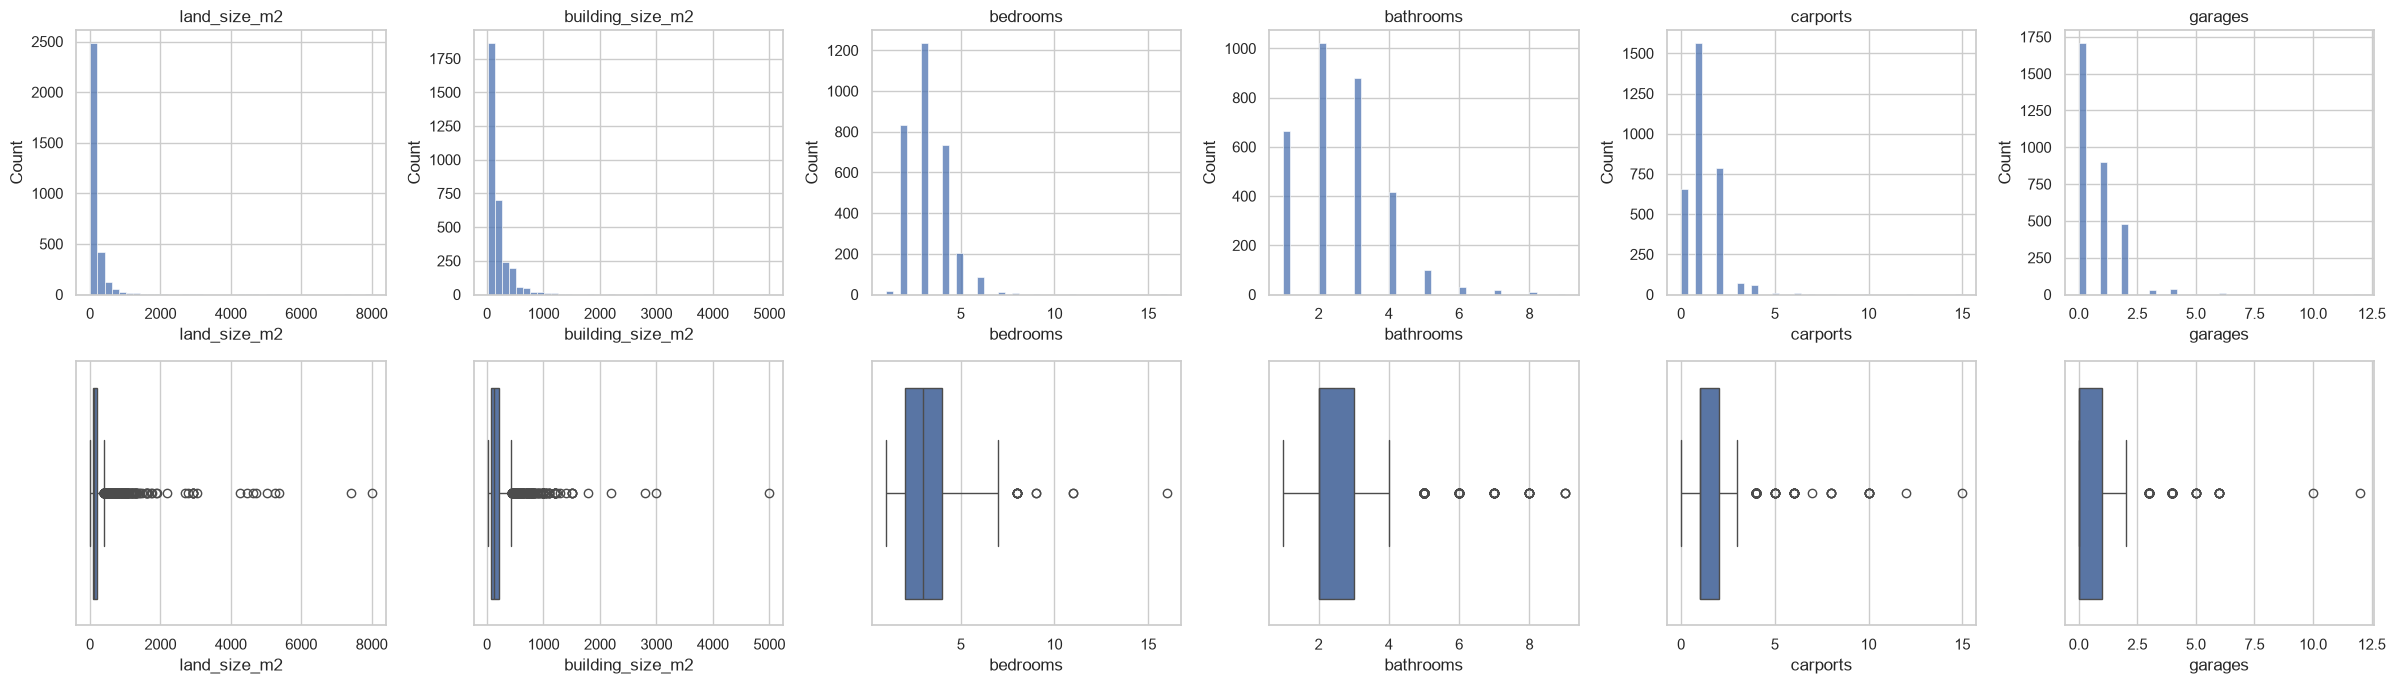

,count,mean,std,min,1%,5%,95%,99%,max
land_size_m2,"3,172.00",200.80,379.04,12.00,30.71,55.00,585.00,"1,314.28","8,000.00"
building_size_m2,"3,172.00",184.52,220.54,19.00,32.00,36.00,548.90,"1,000.00","5,000.00"
bedrooms,"3,141.00",3.22,1.11,1.00,2.00,2.00,5.00,6.00,16.00
bathrooms,"3,146.00",2.52,1.22,1.00,1.00,1.00,5.00,6.00,9.00
carports,"3,172.00",1.21,1.06,0.00,0.00,0.00,3.00,5.00,15.00
garages,"3,172.00",0.70,0.95,0.00,0.00,0.00,2.00,4.00,12.00
price_in_rp,"3,172.00","4,076,831,967.21","10,025,081,676.43","100,000,000.00","223,550,000.00","400,000,000.00","15,500,000,000.00","35,000,000,000.00","250,000,000,000.00"


In [3]:
fig, axes = plt.subplots(2, len(NUMERIK), figsize=(4 * len(NUMERIK), 7))
for i, col in enumerate(NUMERIK):
    sns.histplot(df[col].dropna(), bins=40, ax=axes[0, i]); axes[0, i].set_title(col)
    sns.boxplot(x=df[col], ax=axes[1, i])
plt.tight_layout()
plt.show()

df[NUMERIK + [TARGET]].describe(percentiles=[.01, .05, .95, .99]).T

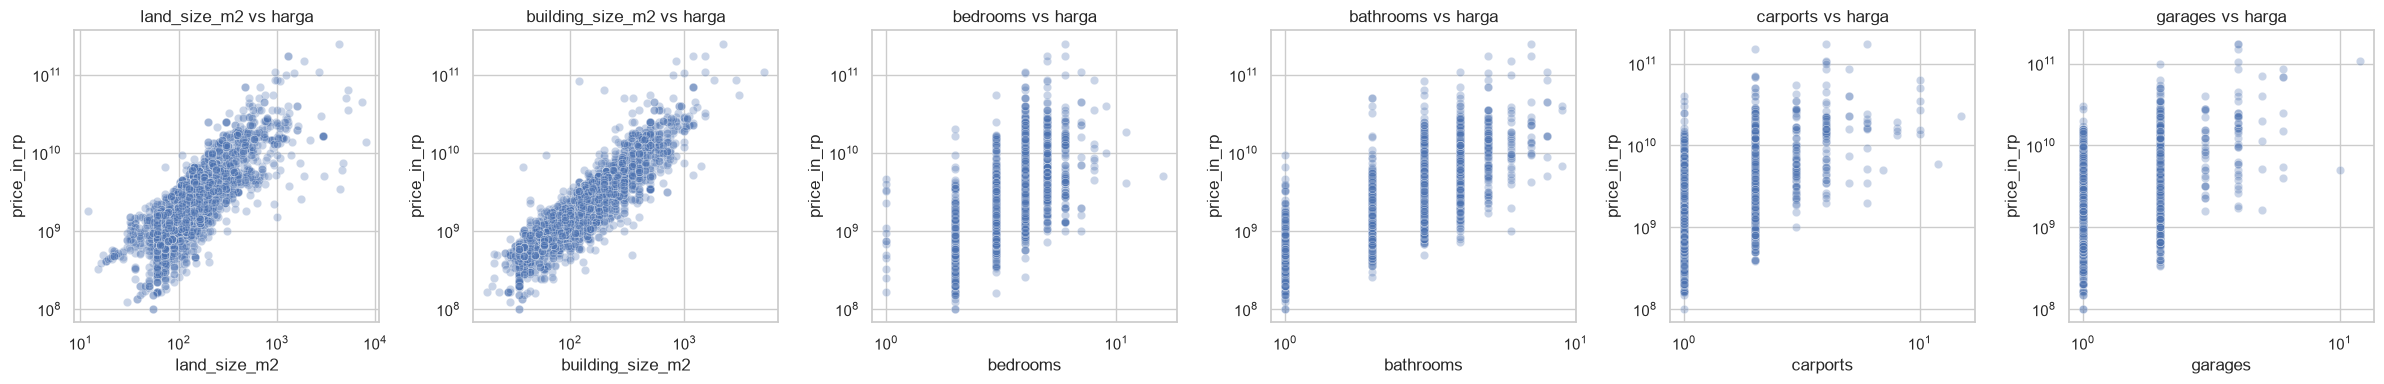

In [4]:
fig, axes = plt.subplots(1, len(NUMERIK), figsize=(4 * len(NUMERIK), 4))
for i, col in enumerate(NUMERIK):
    d = df[df[col] > 0]
    sns.scatterplot(x=d[col], y=d[TARGET], alpha=0.3, ax=axes[i])
    axes[i].set_xscale("log"); axes[i].set_yscale("log")
    axes[i].set_title(f"{col} vs harga")
plt.tight_layout()
plt.show()

,median,jumlah
city,,
Jakarta Utara,"10,000,000,000.00",123
Jakarta Pusat,"7,950,000,000.00",32
Jakarta Selatan,"7,390,000,000.00",217
Jakarta Barat,"3,300,000,000.00",188
Tangerang,"2,500,000,000.00",793
Jakarta Timur,"1,550,000,000.00",81
Bogor,"1,200,000,000.00",748
Bekasi,"975,000,000.00",540
Depok,"962,500,000.00",450


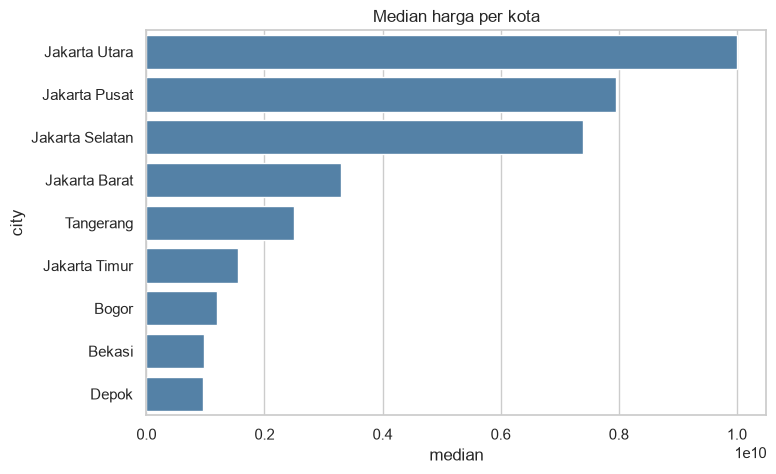

In [5]:
ringkasan = (df.groupby(LOKASI)[TARGET]
               .agg(median="median", jumlah="count")
               .sort_values("median", ascending=False))
display(ringkasan)

plt.figure(figsize=(8, 5))
sns.barplot(x=ringkasan["median"], y=ringkasan.index, color="steelblue")
plt.title("Median harga per kota")
plt.show()

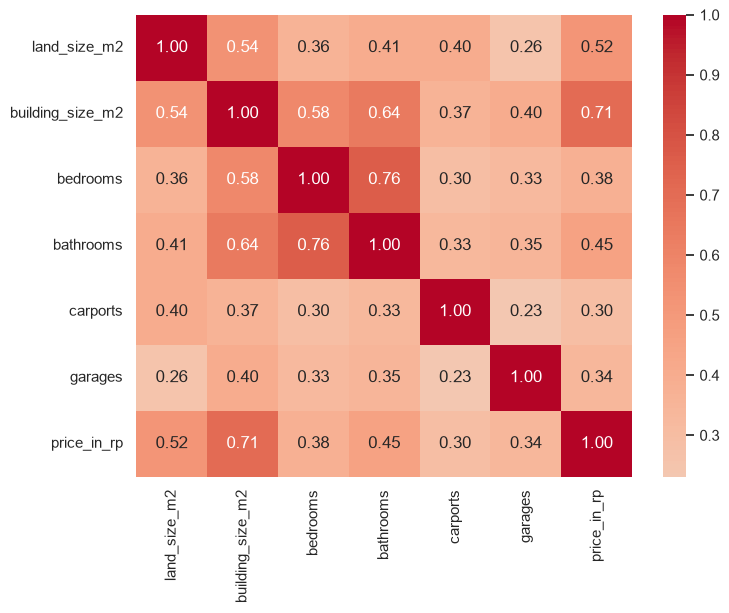

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[NUMERIK + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

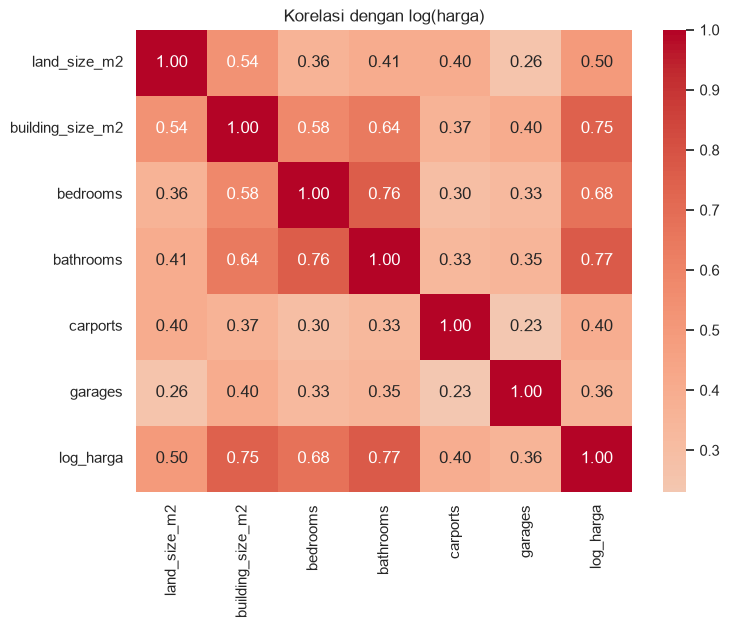

In [7]:
# korelasi terhadap LOG harga (harga asli sangat miring, jadi korelasinya "diremehkan")
d = df[NUMERIK].copy()
d["log_harga"] = np.log(df[TARGET])

plt.figure(figsize=(8, 6))
sns.heatmap(d.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi dengan log(harga)")
plt.show()

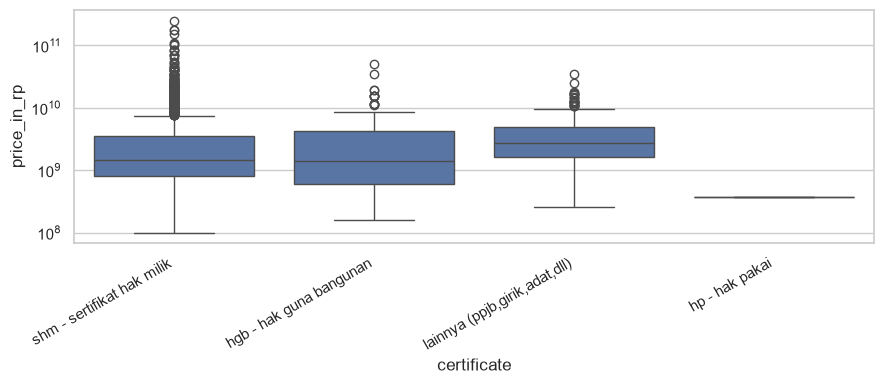

                                        median  count
certificate                                          
lainnya (ppjb,girik,adat,dll) 2,750,000,000.00    188
shm - sertifikat hak milik    1,450,000,000.00   2672
hgb - hak guna bangunan       1,390,000,000.00    181
hp - hak pakai                  375,000,000.00      1


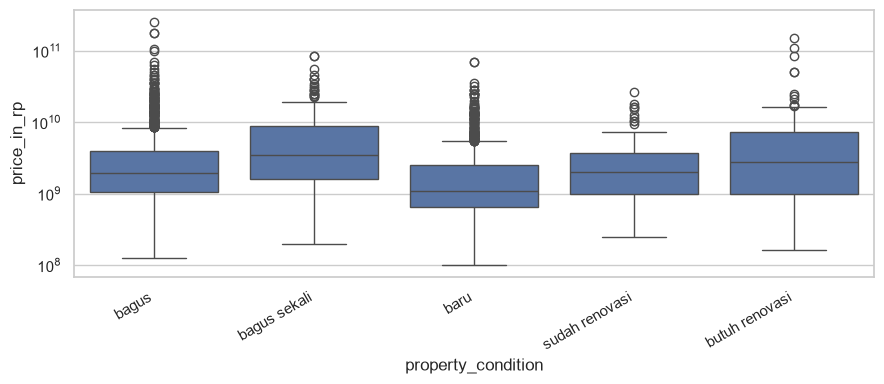

                             median  count
property_condition                        
bagus sekali       3,500,000,000.00    244
butuh renovasi     2,750,000,000.00     87
sudah renovasi     2,000,000,000.00    144
bagus              1,950,000,000.00   1234
baru               1,090,000,000.00   1255


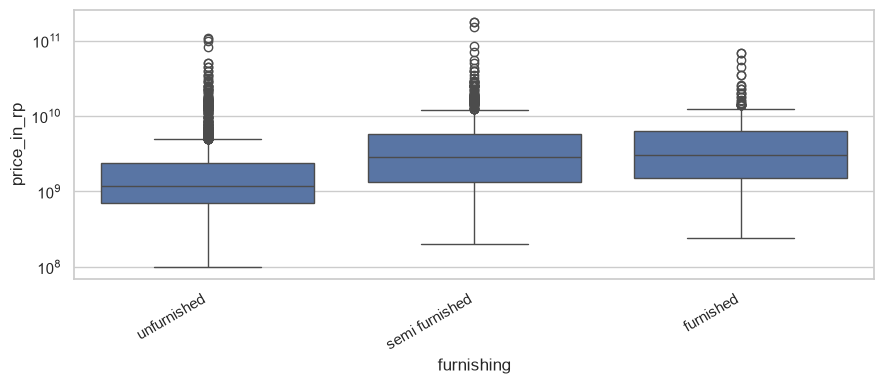

                         median  count
furnishing                            
furnished      3,050,000,000.00    216
semi furnished 2,900,000,000.00    790
unfurnished    1,165,000,000.00   1816


In [8]:
for col in KATEGORI:
    plt.figure(figsize=(9, 4))
    sns.boxplot(data=df, x=col, y=TARGET)
    plt.yscale("log")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
    print(df.groupby(col)[TARGET].agg(["median", "count"]).sort_values("median", ascending=False))

In [9]:
missing = df.isnull().mean().sort_values(ascending=False) * 100
missing[missing > 0]

building_orientation   45.46
building_age           38.18
furnishing             11.03
property_condition      6.56
certificate             4.10
bedrooms                0.98
bathrooms               0.82
floors                  0.13
ads_id                  0.09
dtype: float64

In [10]:
for col in ["building_age", "building_orientation", "furnishing", "property_condition", "certificate"]:
    print(col)
    print(df.groupby(df[col].isna())[TARGET].agg(["median", "count"]))

building_age
                       median  count
building_age                        
False        1,440,000,000.00   1961
True         1,700,000,000.00   1211
building_orientation
                               median  count
building_orientation                        
False                1,560,000,000.00   1730
True                 1,550,000,000.00   1442
furnishing
                     median  count
furnishing                        
False      1,500,000,000.00   2822
True       2,025,000,000.00    350
property_condition
                             median  count
property_condition                        
False              1,560,000,000.00   2964
True               1,440,000,000.00    208
certificate
                      median  count
certificate                        
False       1,500,000,000.00   3042
True        2,975,000,000.00    130


In [11]:
display(df.nlargest(8, "land_size_m2")[["title", "city", "price_in_rp", "land_size_m2", "building_size_m2"]])
display(df[df["carports"] >= 6][["title", "price_in_rp", "carports", "building_size_m2"]])
display(df[df["garages"] >= 5][["title", "price_in_rp", "garages", "building_size_m2"]])

,title,city,price_in_rp,land_size_m2,building_size_m2
1165,"Jual Villa Inc Swimming Pool Tempat Berkuda di Dramaga Bogor, Am 3499",Bogor,"13,900,000,000.00","8,000.00","1,000.00"
1196,DI JUAL RESORT MEWAH DI CIPANAS BESERTA PABRIK,Bogor,"45,000,000,000.00","7,400.00","1,233.00"
1229,Rumah LuasTanah 5360m2 Cilendek Bogor Barat,Bogor,"35,000,000,000.00","5,360.00",624.00
1797,Rumah Hitung Tanah Jagakarsa,Jakarta Selatan,"63,000,000,000.00","5,250.00",200.00
1212,Rumah Cl di Jl. Ciapus Bogor,Bogor,"50,000,000,000.00","5,025.00",300.00
1281,Dijual Villa Bagus Lokasi Dekat Taman Safari di Cisarua Bogor,Bogor,"7,500,000,000.00","4,704.00","1,000.00"
1199,Jual Villa Ada Kolam Renang Lokasi Cipanas Dekat Raya Utama,Bogor,"6,000,000,000.00","4,640.00",500.00
1286,Villa nyaman adem the bess view gunung geulis Gadog,Bogor,"3,500,000,000.00","4,445.00",350.00


,title,price_in_rp,carports,building_size_m2
480,"Rumah Mewah 2 Lantai Tanah Luas Dekat Tol Dan Lrt Caman, Bekasi","6,000,000,000.00",12.00,720.00
686,Rumah perkantoran Dengan Sisa Tanah Luas View Gunung Sentul City,"16,500,000,000.00",8.00,400.00
708,Rumah view gunung dan golf Sentul city,"19,500,000,000.00",6.00,500.00
713,Rumah Atau Perkantoran View Gunung Sentul City,"16,500,000,000.00",6.00,400.00
763,Rumah view golf dan gunung cluster Sentul city,"19,500,000,000.00",8.00,400.00
767,Rumah Atau Perkantoran View Gunung Sentul City,"16,500,000,000.00",6.00,400.00
961,Rumah Idaman Cantik Kamar Tidur 4 di Sentul,"5,000,000,000.00",7.00,369.00
964,Rumah mewah di Permata Sentul.,"5,200,000,000.00",6.00,"1,200.00"
1160,Rumah 1 lantai di Baranangsiang Indah,"2,000,000,000.00",6.00,200.00
1165,"Jual Villa Inc Swimming Pool Tempat Berkuda di Dramaga Bogor, Am 3499","13,900,000,000.00",10.00,"1,000.00"


,title,price_in_rp,garages,building_size_m2
549,Rumah Mewah Dan Elit Lokasi Super Strategis Di Sentul City Bogor,"5,500,000,000.00",6.00,400.00
1203,Jual Cepat Rumah Bagus Untuk Villa di Megamendung,"5,000,000,000.00",10.00,500.00
1917,Dijual rumah mewah katamaran pik brand new lokasi bagus depan taman,"25,000,000,000.00",6.00,750.00
1940,Rumah Luas & Mewah Jakarta Selatan & Sekitarnya,"40,000,000,000.00",5.00,600.00
2036,Rumah di Kemang Jakarta Selatan 950 M2 2 Lantai Kolam Renang SHM,"19,900,000,000.00",5.00,950.00
2102,Rumah Paling Luas Di Pantai Mutiara 3 Lantai Perlu Finishing,"108,000,000,000.00",12.00,"5,000.00"
2123,Rumah American Klasik Sangat Mewah Sekali Full Furnished,"69,000,000,000.00",6.00,"1,200.00"
2124,"Rumah Brand New Menteng 3,5 Lantai Lift Pool Furnish Kotak Dijual 69m","69,000,000,000.00",6.00,"1,200.00"
2221,RUMAH MEWAH SIAP HUNI DEKAT PERKANTORAN DI MAMPANG PRAPATAN,"11,200,000,000.00",5.00,606.00
2264,Rumah ASRI Tanah LUAS akses Jalan BESAR Strategis dkt CILANDAK,"15,000,000,000.00",6.00,450.00
